<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/02_pytorch_classification_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. PyTorch Classification Exercises

The following is a template for 02. PyTorch Classification exercises.

It's only starter code and it's your job to fill in the blanks.

Because of the flexibility of PyTorch, there may be more than one way to answer the question.

Don't worry about trying to be *right* just try writing code that suffices the question.

## Resources
* These exercises are based on [notebook 02 of the learn PyTorch course](https://www.learnpytorch.io/02_pytorch_classification/).
* You can see one form of [solutions on GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions) (but try the exercises below yourself first!).

In [93]:
# Import torch
from sympy import true
import torch
from torch import nn
import matplotlib.pyplot as plt
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() == True else "cpu"
print(device)
# Setup random seed
RANDOM_SEED = 42

cpu


## 1. Make a binary classification dataset with Scikit-Learn's [`make_moons()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) function.
  * For consistency, the dataset should have 1000 samples and a `random_state=42`.
  * Turn the data into PyTorch tensors. 
  * Split the data into training and test sets using `train_test_split` with 80% training and 20% testing.

In [54]:
# Create a dataset with Scikit-Learn's make_moons()
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
samples = 1000

X, y = make_moons(n_samples= samples, noise= 0.2)

print(X.shape)
print(y.shape)

X = torch.from_numpy(X).to(dtype= torch.float32)
y = torch.from_numpy(y).to(dtype = torch.float32)

(1000, 2)
(1000,)


In [55]:
# Turn data into a DataFrame
import pandas as pd

df = pd.DataFrame({"Dimension X1": X[:,0], "Dimension X2": X[:,1], "Classes y": y})
display(df.head(5))



,Dimension X1,Dimension X2,Classes y
0,0.543606,0.760835,0.0
1,1.148899,-0.667410,1.0
2,0.132505,0.172323,1.0
3,-1.047627,0.151496,0.0
4,0.857675,0.261950,0.0


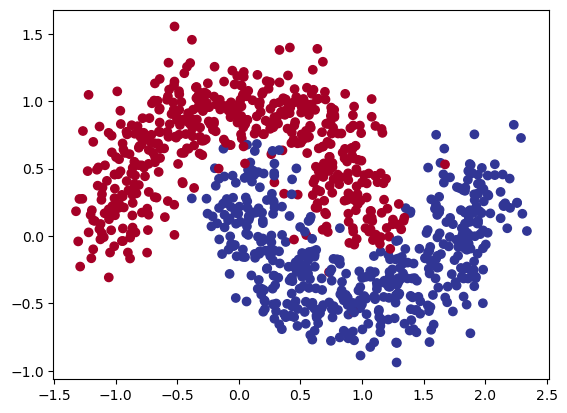

In [56]:
# Visualize the data on a scatter plot
import matplotlib.pyplot as plt

plt.scatter(X[:,0], X[:,1], c= y, cmap=plt.cm.RdYlBu)

In [57]:
# Turn data into tensors of dtype float
from numpy import dtype, long




# Split the data into train and test sets (80% train, 20% test)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= RANDOM_SEED)




### Definition eines quadratischen Knotenpunktes:

In [58]:

class Quad(nn.Module):
    def __init__(self, in_features: int, out_features: int = 1):
        super().__init__()
        self.A = nn.Parameter(torch.randn(out_features, in_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features, in_features))
        self.c = nn.Parameter(torch.zeros(out_features))

    def forward(self, x):
        # x: (batch, in_features)
        quad = torch.einsum('bi,oij,bj->bo', x, self.A, x)   # x^T A x, pro Sample & Output
        lin = x @ self.b.T                                    # b^T x
        return quad + lin + self.c

## 2. Build a model by subclassing `nn.Module` that incorporates non-linear activation functions and is capable of fitting the data you created in 1.
  * Feel free to use any combination of PyTorch layers (linear and non-linear) you want.

In [136]:
import torch
from torch import nn

# Inherit from nn.Module to make a model capable of fitting the mooon data
class MoonModelV0(nn.Module):
    def __init__(self, input = 2, output = 1, hidden = 5, **kwargs):
        super().__init__()
        self.network = nn.Sequential(
            Quad(in_features = input, out_features = hidden),
            nn.ReLU(),
            Quad(in_features = hidden, out_features= hidden),
            nn.ReLU(),
            Quad(in_features = hidden, out_features = output),
        )

    def forward(self, x):
        logits = self.network(x)
        return logits

# Instantiate the model
model_v1 = MoonModelV0(hidden = 10)

## 3. Setup a binary classification compatible loss function and optimizer to use when training the model built in 2.

In [137]:
# Setup loss function
loss_func = nn.BCEWithLogitsLoss()

# Setup optimizer to optimize model's parameters
optimizer = torch.optim.Adam(params= model_v1.parameters(), lr = 0.01)

## 4. Create a training and testing loop to fit the model you created in 2 to the data you created in 1.
  * Do a forward pass of the model to see what's coming out in the form of logits, prediction probabilities and labels.
  * To measure model accuray, you can create your own accuracy function or use the accuracy function in [TorchMetrics](https://torchmetrics.readthedocs.io/en/latest/).
  * Train the model for long enough for it to reach over 96% accuracy.
  * The training loop should output progress every 10 epochs of the model's training and test set loss and accuracy.

In [129]:

# What's coming out of our model?

# logits (raw outputs of model)
preds = model_v1.forward(X)
print("Logits:", preds[:5])
## Your code here ##

# Prediction probabilities
props = torch.round(torch.sigmoid(model_v1.forward(X)))
print("Pred probs:", props[:5])
## Your code here ##

# Prediction labels
pred_label = props
print("Pred labels:", pred_label[:5])
## Your code here ##

pred_label.shape

Logits: tensor([[1.3577e-12],
        [3.7257e-09],
        [5.1679e-17],
        [7.7418e-15],
        [6.7979e-12]], grad_fn=<SliceBackward0>)
Pred probs: tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], grad_fn=<SliceBackward0>)
Pred labels: tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], grad_fn=<SliceBackward0>)


torch.Size([1000, 1])

In [103]:
from torchmetrics import Accuracy

accuracy_func = Accuracy(task = "binary", num_classes= 2).to(device)
# Let's calculuate the accuracy using accuracy from TorchMetrics


## TODO: Uncomment this code to use the Accuracy function
print(accuracy_func(y, pred_label.squeeze()))

tensor(0.5000)


In [64]:
y_logits = model_v1(X_train).squeeze()
y_pred = torch.round(torch.sigmoid(y_logits))
print(y_logits.dtype, y_logits.shape, y_train.dtype, y_train.shape)

torch.float32 torch.Size([800]) torch.float32 torch.Size([800])


In [138]:
torch.manual_seed(RANDOM_SEED)

EPOCHS = 3000

X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

model_v1.to(device)

for epoch in range(EPOCHS):
    model_v1.train()

    y_logits = model_v1(X_train)
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_func(y_logits, y_train.unsqueeze(dim = 1))
    acc = accuracy_func(y_pred,y_train.unsqueeze(dim = 1))

    optimizer.zero_grad()

    loss.backward()
    
    optimizer.step()

    model_v1.eval()
    with torch.inference_mode():
        y_logits_test = model_v1.forward(X_test)
        y_pred_test = torch.round(torch.sigmoid(y_logits_test))

        test_loss = loss_func(y_logits_test, y_test.unsqueeze(dim = 1))
        test_acc = accuracy_func(y_pred_test, y_test.unsqueeze(dim = 1))
    if epoch % round((EPOCHS*0.1), 0) == 0:
        print(f"|Epoch: {epoch:>5}|| Loss: {loss:10.5f}|| Acc: {acc:6.2f}|| Test Loss: {test_loss: 10.5f}|| Test Acc: {test_acc:6.2f}|")

|Epoch:     0|| Loss:    0.69385|| Acc:   0.30|| Test Loss:    0.69361|| Test Acc:   0.44|
|Epoch:   300|| Loss:    0.05490|| Acc:   0.98|| Test Loss:    1.14759|| Test Acc:   0.98|
|Epoch:   600|| Loss:    0.05397|| Acc:   0.98|| Test Loss:    1.33512|| Test Acc:   0.98|
|Epoch:   900|| Loss:    0.08194|| Acc:   0.97|| Test Loss:    0.18424|| Test Acc:   0.98|
|Epoch:  1200|| Loss:    0.05387|| Acc:   0.98|| Test Loss:    1.17470|| Test Acc:   0.98|
|Epoch:  1500|| Loss:    0.05179|| Acc:   0.98|| Test Loss:    1.56203|| Test Acc:   0.98|
|Epoch:  1800|| Loss:    0.05168|| Acc:   0.99|| Test Loss:    1.83186|| Test Acc:   0.97|
|Epoch:  2100|| Loss:    0.04310|| Acc:   0.99|| Test Loss:    2.90890|| Test Acc:   0.97|
|Epoch:  2400|| Loss:    0.03455|| Acc:   0.99|| Test Loss:    3.53033|| Test Acc:   0.97|
|Epoch:  2700|| Loss:    0.08286|| Acc:   0.98|| Test Loss:    2.07897|| Test Acc:   0.98|


## 5. Make predictions with your trained model and plot them using the `plot_decision_boundary()` function created in this notebook.

In [139]:
# Plot the model predictions
import numpy as np

def plot_decision_boundary(model, X, y):
  
    # Put everything to CPU (works better with NumPy + Matplotlib)
    model.to("cpu")
    X, y = X.to("cpu"), y.to("cpu")

    # Source - https://madewithml.com/courses/foundations/neural-networks/ 
    # (with modifications)
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101), 
                         np.linspace(y_min, y_max, 101))

    # Make features
    X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float()

    # Make predictions
    model.eval()
    with torch.inference_mode():
        y_logits = model(X_to_pred_on)

    # Test for multi-class or binary and adjust logits to prediction labels
    if len(torch.unique(y)) > 2:
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # mutli-class
    else: 
        y_pred = torch.round(torch.sigmoid(y_logits)) # binary
    
    # Reshape preds and plot
    y_pred = y_pred.reshape(xx.shape).detach().numpy()
    plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

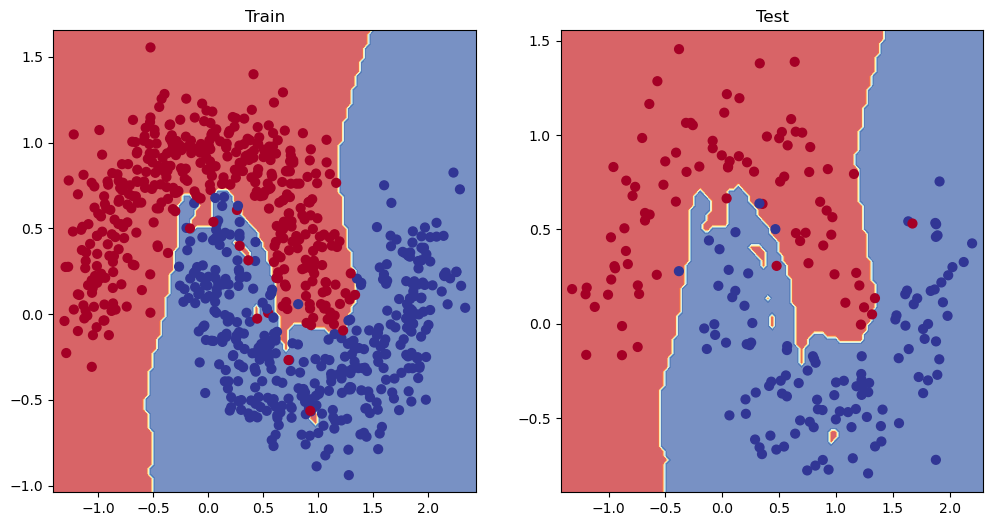

In [140]:
# Plot decision boundaries for training and test sets

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_v1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_v1, X_test, y_test)

# fig, ax = plt.subplots(1, 2, figsize = (12,6))
# ax[0] = plot_decision_boundary(model_v1, X_train, y_train)
# #ax[0].set_title("Train")
# ax[1] = plot_decision_boundary(model_v1, X_test, y_test)
# #ax[1].set_title("Test")
# fig.show()

## 6. Replicate the Tanh (hyperbolic tangent) activation function in pure PyTorch.
  * Feel free to reference the [ML cheatsheet website](https://ml-cheatsheet.readthedocs.io/en/latest/activation_functions.html#tanh) for the formula.

In [144]:
# Create a straight line tensor
straight_line = torch.linspace(-5, 5, 50)


Text(0, 0.5, 'y')

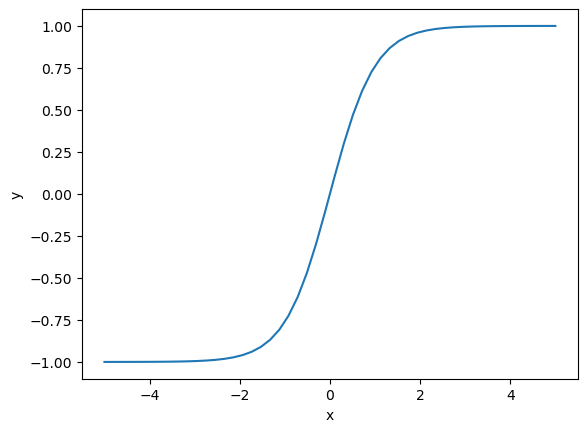

In [151]:
# Test torch.tanh() on the tensor and plot it
hyperbolicus =torch.tanh(straight_line)

fig, ax = plt.subplots()      # Tupel-Unpacking: (Figure, Axes)
ax.plot(straight_line, hyperbolicus)                 # auf dem Axes zeichnen
ax.set_xlabel("x")
ax.set_ylabel("y")

In [ ]:
# Replicate torch.tanh() and plot it


## 7. Create a multi-class dataset using the [spirals data creation function from CS231n](https://cs231n.github.io/neural-networks-case-study/) (see below for the code).
  * Split the data into training and test sets (80% train, 20% test) as well as turn it into PyTorch tensors.
  * Construct a model capable of fitting the data (you may need a combination of linear and non-linear layers).
  * Build a loss function and optimizer capable of handling multi-class data (optional extension: use the Adam optimizer instead of SGD, you may have to experiment with different values of the learning rate to get it working).
  * Make a training and testing loop for the multi-class data and train a model on it to reach over 95% testing accuracy (you can use any accuracy measuring function here that you like) - 1000 epochs should be plenty.
  * Plot the decision boundaries on the spirals dataset from your model predictions, the `plot_decision_boundary()` function should work for this dataset too.

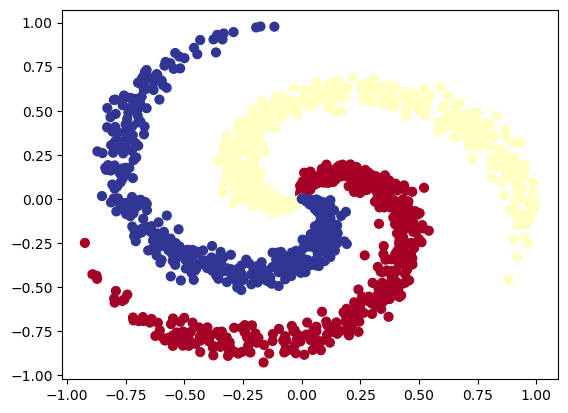

In [163]:
# Code for creating a spiral dataset from CS231n
import numpy as np
import matplotlib.pyplot as plt
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
N = 500 # number of points per class
D = 2 # dimensionality
K = 3 # number of classes
X = np.zeros((N*K,D)) # data matrix (each row = single example)
y = np.zeros(N*K, dtype='uint8') # class labels
for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix] = j
# lets visualize the data
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
plt.show()

In [164]:
# Turn data into tensors
import torch
X = torch.from_numpy(X).type(torch.float) # features as float32
y = torch.from_numpy(y).type(torch.LongTensor) # labels need to be of type long


In [171]:

# Create train and test splits
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size= 0.8)

X_train.shape, X_test.shape,

y_train

tensor([1, 2, 2,  ..., 0, 0, 1])

In [167]:
# Let's calculuate the accuracy for when we fit our model

from torchmetrics import Accuracy

## TODO: uncomment the two lines below to send the accuracy function to the device
acc_fn = Accuracy(task="multiclass", num_classes=4).to(device)
acc_fn

MulticlassAccuracy()

In [241]:
# Prepare device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create model by subclassing nn.Module
class SpiralFucker3000(nn.Module):
    def __init__(self, input:int = 2, hidden:int = 10, output:int = 3, **kwargs):
        super().__init__()
        self.spiral_network = nn.Sequential(
            Quad(in_features= input, out_features= hidden),
            nn.ReLU(),
            Quad(in_features= hidden, out_features= output),
        )

    def forward(self, x: torch.Tensor):
        logits = self.spiral_network(x)
        return logits

# Instantiate model and send it to device
model_v2 = SpiralFucker3000()


In [230]:
# Setup data to be device agnostic
X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

# Print out first 10 untrained model outputs (forward pass)
logits = model_v2.forward(X_train)
print("Logits:", logits[:10], "Logits Shape:", logits.shape)
## Your code here ##

preds = torch.softmax(logits, dim=1)
print("Pred probs:", preds,"Pred Shape:", preds.shape)
## Your code here ##

labels = preds.argmax(dim= 1)
print("Pred labels:", labels)
## Your code here ##

Logits: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]], grad_fn=<SliceBackward0>) Logits Shape: torch.Size([1200, 3])
Pred probs: tensor([[0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333],
        ...,
        [0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333]], grad_fn=<SoftmaxBackward0>) Pred Shape: torch.Size([1200, 3])
Pred labels: tensor([0, 0, 0,  ..., 0, 0, 0])


In [242]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model_v2.parameters(), lr= 0.1)

In [243]:
import matplotlib.pyplot as plt

EPOCHS = 2000

TRAIN_Loss = []
TEST_Loss = []

for epoch in range(EPOCHS):
    model_v2.train()
    #Forward Pass
    logit = model_v2.forward(X_train)
    pred = torch.softmax(logit, dim= 1).argmax(dim = 1)

    #Loss
    train_loss = loss_fn(logit, y_train)

    #Accuracy
    train_acc = acc_fn(pred, y_train)

    #Zero Gradient
    optimizer.zero_grad()

    #Backpropagation
    train_loss.backward()

    #Stepping
    optimizer.step()

    #Testing
    model_v2.eval()

    with torch.inference_mode():
        test_logit = model_v2.forward(X_test)
        test_pred = torch.softmax(test_logit, dim= 1).argmax(dim = 1)

        #Test Loss
        test_loss = loss_fn(test_logit, y_test)
        #Test Accuracy
        test_acc = acc_fn(test_pred, y_test)

    TRAIN_Loss.append(train_loss.item())
    TEST_Loss.append(test_loss.item())

    if epoch % round(EPOCHS*0.1, 0)== 0:
        print(f"Epoch:{epoch:<5} || Loss: {train_loss: 10.4f} || Acc: {train_acc: 6.2f} || Test Loss: {test_loss: 10.4f} || Test Acc: {test_acc: 6.2f}")
        


Epoch:0     || Loss:     1.0985 || Acc:   0.37 || Test Loss:     1.0579 || Test Acc:   0.45
Epoch:200   || Loss:     0.0145 || Acc:   1.00 || Test Loss:     0.0139 || Test Acc:   1.00
Epoch:400   || Loss:     0.0082 || Acc:   1.00 || Test Loss:     0.0073 || Test Acc:   1.00
Epoch:600   || Loss:     0.0065 || Acc:   1.00 || Test Loss:     0.0064 || Test Acc:   1.00
Epoch:800   || Loss:     0.0055 || Acc:   1.00 || Test Loss:     0.0072 || Test Acc:   1.00
Epoch:1000  || Loss:     0.0052 || Acc:   1.00 || Test Loss:     0.0119 || Test Acc:   1.00
Epoch:1200  || Loss:     0.0048 || Acc:   1.00 || Test Loss:     0.0212 || Test Acc:   1.00
Epoch:1400  || Loss:     0.0051 || Acc:   1.00 || Test Loss:     0.0220 || Test Acc:   1.00
Epoch:1600  || Loss:     0.0044 || Acc:   1.00 || Test Loss:     0.0198 || Test Acc:   1.00
Epoch:1800  || Loss:     0.0044 || Acc:   1.00 || Test Loss:     0.0188 || Test Acc:   1.00


/var/folders/bd/jt99k0p569j1j60f7kqyhhyr0000gn/T/ipykernel_89407/2985952603.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


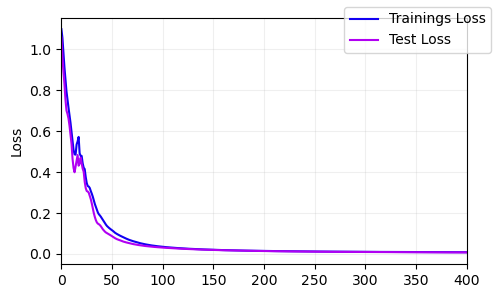

In [246]:

fig, ax = plt.subplots(1, figsize = (5,3))
ax.plot(range(EPOCHS), TRAIN_Loss, label = "Trainings Loss", color = "#1200f2")
ax.plot(range(EPOCHS), TEST_Loss, label = "Test Loss", color = "#b100f2")
ax.grid(alpha=.2)
ax.set_ylabel("Loss")
ax.set_xlim(0, 400)
fig.legend()
fig.tight_layout()
fig.show()

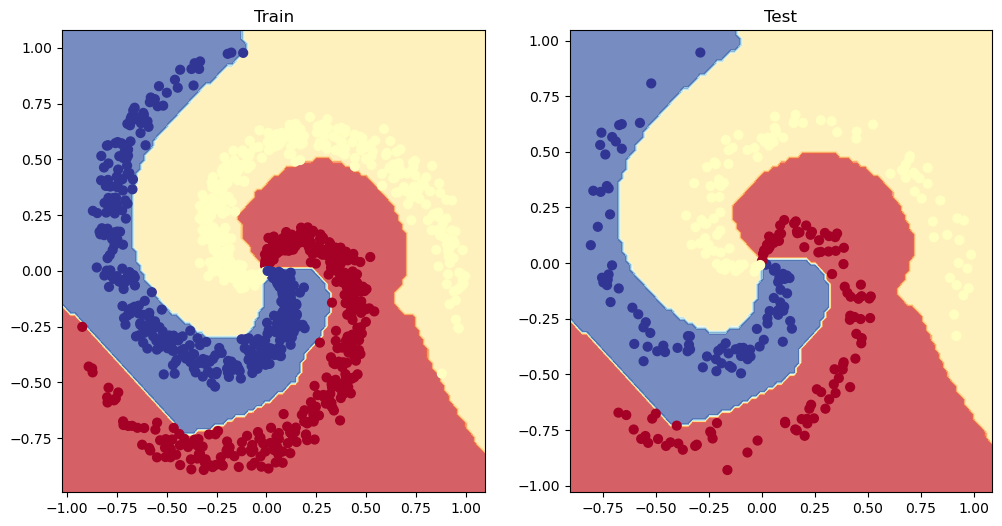

In [247]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_v2, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_v2, X_test, y_test)

In [248]:
model_v2.state_dict

<bound method Module.state_dict of SpiralFucker3000(
  (spiral_network): Sequential(
    (0): Quad()
    (1): ReLU()
    (2): Quad()
  )
)>